# Laboratorio 11 — Búsqueda eficiente de rostros con pgvector
**Base de Datos II · UTEC · Prof. Heider Sánchez**

Las pruebas se corrieron en una MacBook Pro M1 (8 núcleos) con 16 GB de RAM, PostgreSQL 16 con pgvector 0.8.7 en Docker

---
## P0. Preparación

In [1]:
import os, glob, re, time, statistics, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import face_recognition
import psycopg2
from psycopg2.extras import execute_values
from pgvector.psycopg2 import register_vector

DATASET_PATH = "/Users/luciagurbillon/Documents/BD2/Lab_11/data/lfw"

coleccion = pd.DataFrame([
    {"person": os.path.basename(os.path.dirname(p)), "path": p}
    for p in glob.iglob(os.path.join(DATASET_PATH, "**", "*.jpg"), recursive=True)
])
print(len(coleccion), "imágenes")

13233 imágenes


In [2]:
coleccion = coleccion.sort_values("path").reset_index(drop=True)
coleccion.head()

,person,path
0,AJ_Cook,/Users/luciagurbillon/Documents/BD2/Lab_11/dat...
1,AJ_Lamas,/Users/luciagurbillon/Documents/BD2/Lab_11/dat...
2,Aaron_Eckhart,/Users/luciagurbillon/Documents/BD2/Lab_11/dat...
3,Aaron_Guiel,/Users/luciagurbillon/Documents/BD2/Lab_11/dat...
4,Aaron_Patterson,/Users/luciagurbillon/Documents/BD2/Lab_11/dat...


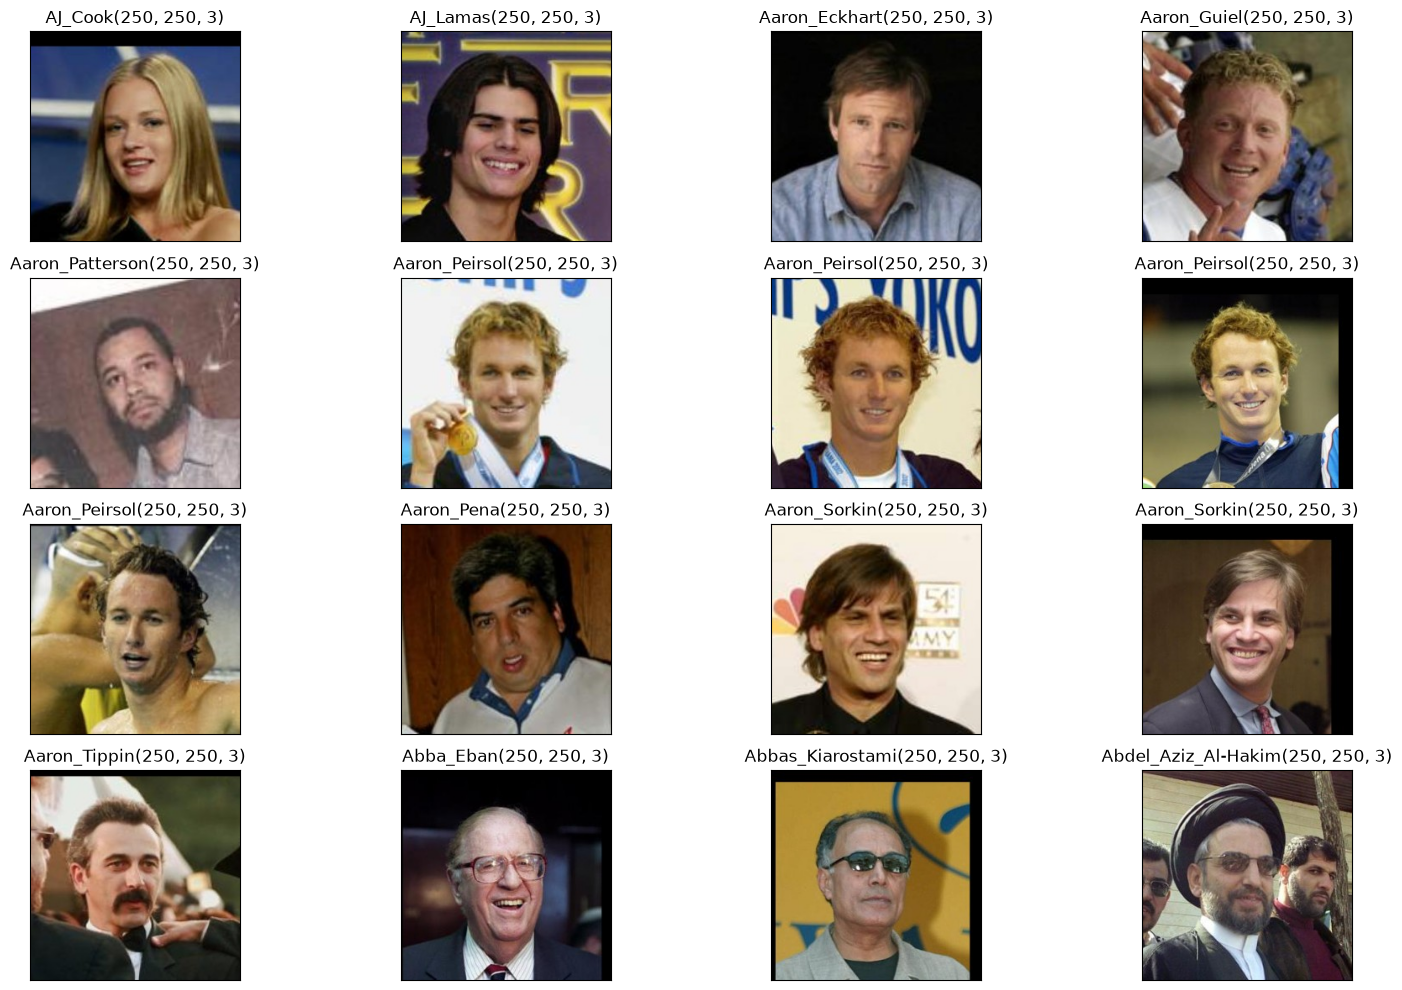

In [3]:
def mostrarFotos(coleccion, posiciones):
    plt.figure(figsize=(16, 10))
    for i, idx in enumerate(posiciones):
        img = plt.imread(coleccion.path.iloc[idx])
        plt.subplot(4, 4, i + 1)
        plt.imshow(img)
        plt.title(coleccion.person.iloc[idx] + str(img.shape))
        plt.xticks([]); plt.yticks([])
    plt.tight_layout()
    plt.show()

mostrarFotos(coleccion, list(range(16)))

### Exploración del dataset

In [4]:
fotos_por_persona = coleccion.person.value_counts()
print("personas distintas:", len(fotos_por_persona))
print("personas con una sola foto:", (fotos_por_persona == 1).sum())
print("personas con 10 fotos o más:", (fotos_por_persona >= 10).sum())
fotos_por_persona.head(10)

personas distintas: 5749
personas con una sola foto: 4069
personas con 10 fotos o más: 158


person
George_W_Bush        530
Colin_Powell         236
Tony_Blair           144
Donald_Rumsfeld      121
Gerhard_Schroeder    109
Ariel_Sharon          77
Hugo_Chavez           71
Junichiro_Koizumi     60
Jean_Chretien         55
John_Ashcroft         53
Name: count, dtype: int64

Se nota que la data está desbalanceada, hay 5749 personas y 4069 de ellas tienen una sola foto, mientras George W. Bush tiene 530

Esto pasa porque LFW sale de fotos de noticias. En ese momento la tendencia era la guerra de Iraq, entonces salía más el presidente de USA y sus secretarios (Colin Powell, Donald Rumsfeld) o Tony Blair, mientras deportistas y actores salían con menos frecuencia. El desbalance se da por la naturaleza de la fuente de los datos

---
## P1. Generar y almacenar los vectores
### P1.1 Extracción de embeddings

In [5]:
def generate_face_embeddings(coleccion, n):
    registros = []
    for i, fila in enumerate(coleccion.head(n).itertuples()):
        imagen = face_recognition.load_image_file(fila.path)
        encodings = face_recognition.face_encodings(imagen)
        if encodings:
            registros.append((fila.person, fila.path, encodings[0]))
        if i % 500 == 0 and i > 0:
            print(i, "procesadas,", len(registros), "con rostro")
    return registros

In [6]:
import pickle
CACHE = "embeddings_lfw.pkl"

t0 = time.time()
if os.path.exists(CACHE):
    todos = pickle.load(open(CACHE, "rb"))
else:
    todos = generate_face_embeddings(coleccion, len(coleccion))
    pickle.dump(todos, open(CACHE, "wb"))

print(len(todos), "imágenes con rostro de", len(coleccion), f"({time.time()-t0:.1f} s)")

13176 imágenes con rostro de 13233 (0.0 s)


### P1.2 Consultas reservadas

In [7]:
df = pd.DataFrame(todos, columns=["person", "path", "embedding"])

conteo = df.person.value_counts()
personas_ok = conteo[conteo >= 2].index
candidatas = df[df.person.isin(personas_ok)]

consultas = (candidatas.groupby("person").sample(1, random_state=42)
                       .sample(100, random_state=42))
base = df.drop(consultas.index)
print("personas con 2 o más fotos con rostro:", len(personas_ok))

personas con 2 o más fotos con rostro: 1672


In [8]:
print(len(base), "filas para la tabla,", len(consultas), "consultas reservadas de", consultas.person.nunique(), "personas")

13076 filas para la tabla, 100 consultas reservadas de 100 personas


### P1.3 Almacenamiento en PostgreSQL

In [9]:
conn = psycopg2.connect(host="localhost", port=5433, user="postgres", password="123456", dbname="postgres")
conn.autocommit = True
cur = conn.cursor()
cur.execute("CREATE EXTENSION IF NOT EXISTS vector")
register_vector(conn)

cur.execute('''
    CREATE TABLE IF NOT EXISTS face_embeddings (
        id SERIAL PRIMARY KEY,
        name TEXT,
        path TEXT,
        embedding VECTOR(128)
    )''')

cur.execute("SELECT extversion FROM pg_extension WHERE extname = 'vector'")
print("pgvector", cur.fetchone()[0])

pgvector 0.8.7


In [10]:
cur.execute("DROP INDEX IF EXISTS face_ivf")
cur.execute("DROP INDEX IF EXISTS face_hnsw")
cur.execute("TRUNCATE face_embeddings RESTART IDENTITY")

registros = list(base.itertuples(index=False, name=None))
t0 = time.time()
execute_values(cur, "INSERT INTO face_embeddings (name, path, embedding) VALUES %s", registros)
print(len(registros), f"filas insertadas ({time.time()-t0:.1f} s)")

13076 filas insertadas (1.4 s)


In [11]:
cur.execute("SELECT COUNT(*), COUNT(DISTINCT name) FROM face_embeddings")
print("filas, personas:", cur.fetchone())

filas, personas: (13076, 5722)


Se descartaron 57 imágenes porque no se detectó rostro, pueden ser fotos muy borrosas, donde no sale el rostro o está tapado, entonces no se reconocen estructuras faciales como ojos o cejas. La tabla quedó con 13076 filas de 5722 personas

Las 100 consultas se separan antes de insertar porque si las metiera, el resultado no sería alguien parecido sino la misma persona, esto sería un tipo de data leakage. Por eso solo se eligen personas con 2 fotos o más, así en la tabla queda otra foto suya para encontrar

---
## P2. Búsqueda kNN lineal y doble famoso

In [12]:
def knn(q, k=10, op="<->"):
    cur.execute(f"SELECT id FROM face_embeddings ORDER BY embedding {op} %s LIMIT %s", (q, k))
    return [r[0] for r in cur.fetchall()]

def knn_lineal(q, k=10, op="<->"):
    cur.execute("SET enable_indexscan = off")
    ids = knn(q, k, op)
    cur.execute("RESET enable_indexscan")
    return ids

In [13]:
def filas_por_id(ids):
    cur.execute("SELECT id, name, path FROM face_embeddings WHERE id = ANY(%s)", (ids,))
    por_id = {i: (name, path) for i, name, path in cur.fetchall()}
    return pd.DataFrame([por_id[i] for i in ids], columns=["person", "path"])

### P2 a) kNN lineal: `<->` (euclidiana) vs `<=>` (coseno)

In [14]:
q = consultas.embedding.iloc[0]
print("consulta:", consultas.person.iloc[0])

def mediana_ms(f, repeticiones=10):
    tiempos = []
    for _ in range(repeticiones):
        t0 = time.perf_counter()
        f()
        tiempos.append((time.perf_counter() - t0) * 1000)
    return statistics.median(tiempos)

ids_l2 = knn_lineal(q, 10, "<->")
ids_cos = knn_lineal(q, 10, "<=>")
ms_l2 = mediana_ms(lambda: knn_lineal(q, 10, "<->"))
ms_cos = mediana_ms(lambda: knn_lineal(q, 10, "<=>"))

print(f"<-> mediana: {ms_l2:.2f} ms")
print(f"<=> mediana: {ms_cos:.2f} ms")
print("mismo orden:", ids_l2 == ids_cos, "| mismo conjunto:", set(ids_l2) == set(ids_cos),
      "| en común:", len(set(ids_l2) & set(ids_cos)), "de 10")

normas = np.linalg.norm(np.array(base.embedding.tolist()), axis=1)
print(f"normas de los embeddings: min {normas.min():.3f}, max {normas.max():.3f}, media {normas.mean():.3f}")

pd.DataFrame({"<->": filas_por_id(ids_l2).person, "<=>": filas_por_id(ids_cos).person})

consulta: Emma_Thompson
<-> mediana: 2.82 ms
<=> mediana: 2.73 ms
mismo orden: False | mismo conjunto: False | en común: 7 de 10
normas de los embeddings: min 1.189, max 1.702, media 1.426


,<->,<=>
0,Sylvie_Guillem,Sylvie_Guillem
1,Emma_Thompson,Emma_Thompson
2,Emma_Thompson,Emma_Thompson
3,Tori_Amos,Tori_Amos
4,Erin_Runnion,Elsa_Zylberstein
5,Elsa_Zylberstein,Erin_Runnion
6,Princess_Anne,Sadie_Frost
7,Nancy_Pelosi,Princess_Diana
8,Benazir_Bhutto,Nancy_Pelosi
9,Marisol_Martinez_Sambran,Mary_Steenburgen


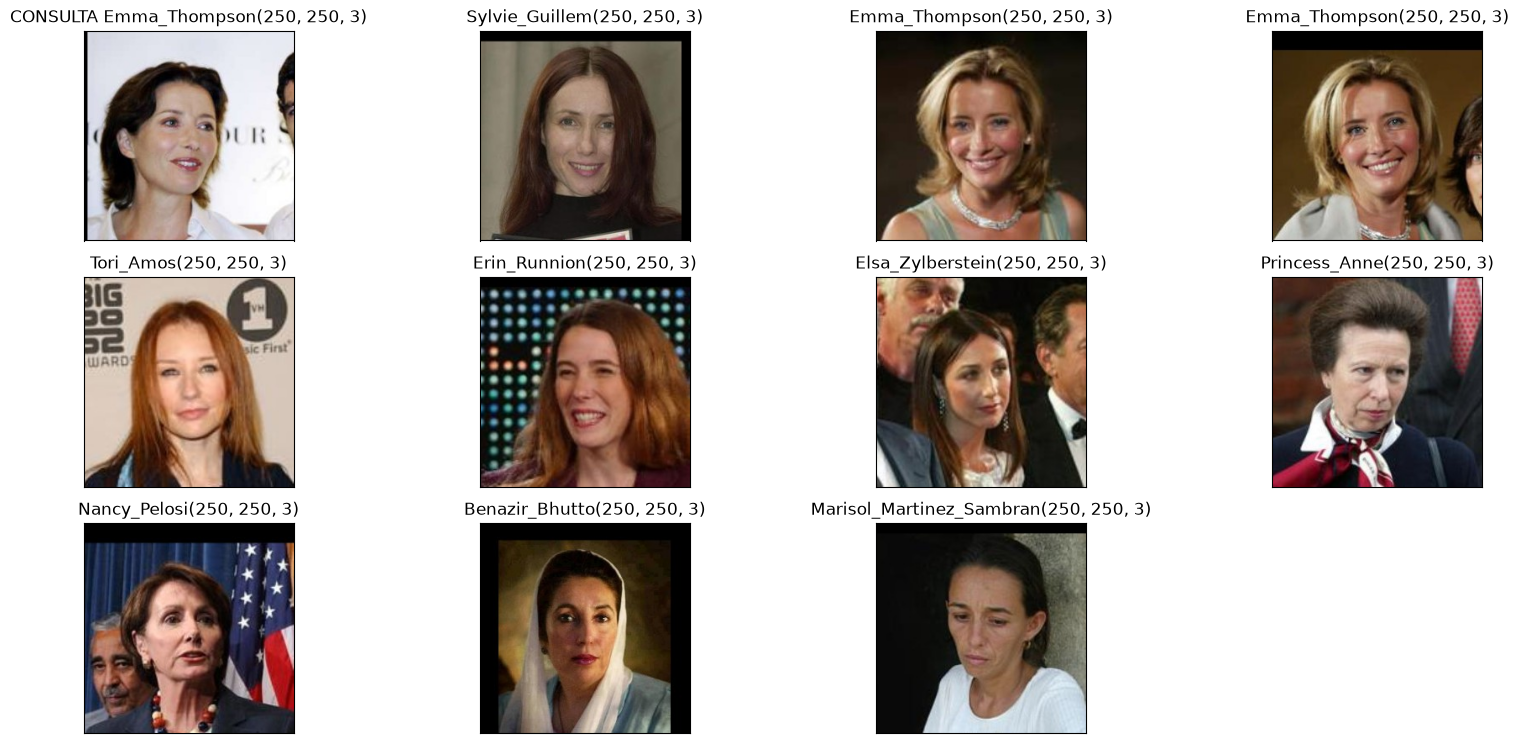

In [15]:
vecinos = pd.concat([pd.DataFrame([("CONSULTA " + consultas.person.iloc[0], consultas.path.iloc[0])], columns=["person", "path"]),
                     filas_por_id(ids_l2)], ignore_index=True)
mostrarFotos(vecinos, list(range(len(vecinos))))

Difieren un poco nada más, los 4 primeros son iguales y hay 7 de 10 en común. Esto pasa porque las normas de los vectores varían un poco (de 1.19 a 1.70), no tanto como para diferir mucho, pero sí lo suficiente para cambiar el orden de los vecinos que están a distancias muy parecidas. Los tiempos son casi iguales porque las dos son búsqueda lineal y recorren las 13076 filas, el coseno solo agrega una división por las normas

### P2 b) Doble famoso

In [16]:
def famoso_parecido(q, candidatos=50, top=5):
    cur.execute('''
        SELECT name, MIN(dist) AS dist, COUNT(*) AS fotos
        FROM (SELECT name, embedding <-> %s AS dist
              FROM face_embeddings ORDER BY embedding <-> %s LIMIT %s) t
        GROUP BY name ORDER BY dist LIMIT %s''', (q, q, candidatos, top))
    return cur.fetchall()

mi_foto = face_recognition.face_encodings(face_recognition.load_image_file("mi_foto.jpg"))[0]
cur.execute("SET enable_indexscan = off")
dobles_lineal = famoso_parecido(mi_foto)
cur.execute("RESET enable_indexscan")
pd.DataFrame(dobles_lineal, columns=["name", "dist", "fotos"])

,name,dist,fotos
0,Zarai_Toledo,0.464538,1
1,Nadia_Forte,0.526628,1
2,Megawati_Sukarnoputri,0.540812,16
3,Hana_Makhmalbaf,0.548615,1
4,Florencia_Kirchner,0.560280,1


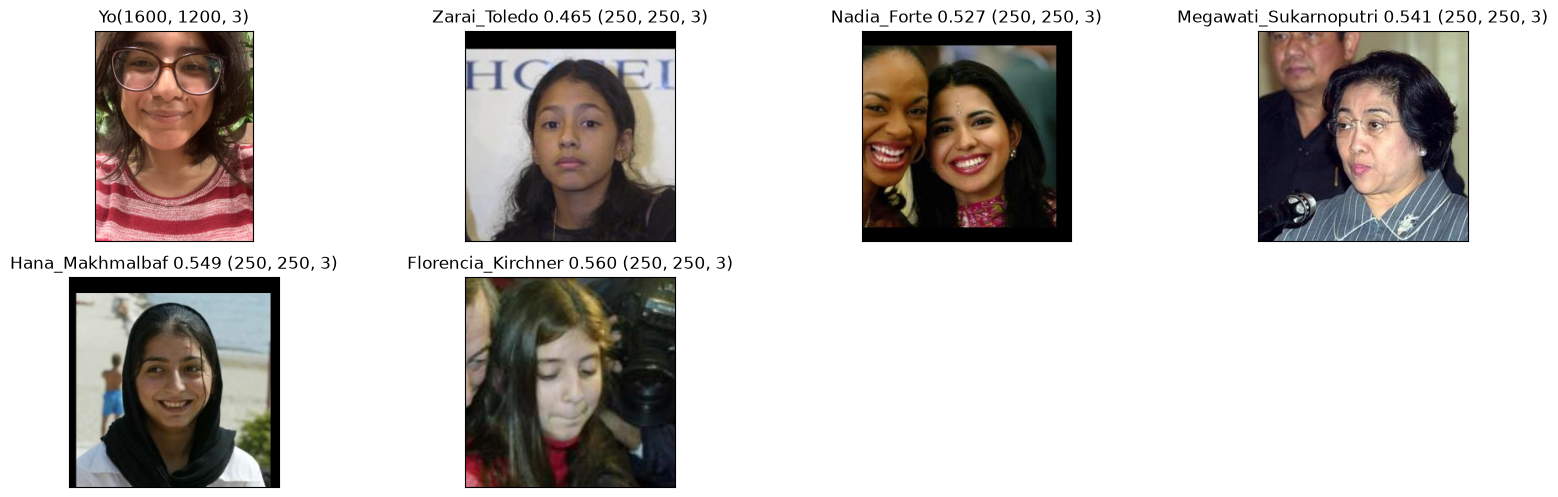

In [17]:
filas = [("Yo", "mi_foto.jpg")]
for name, dist, fotos in dobles_lineal:
    cur.execute("SELECT path FROM face_embeddings WHERE name = %s ORDER BY embedding <-> %s LIMIT 1", (name, mi_foto))
    filas.append((f"{name} {dist:.3f} ", cur.fetchone()[0]))
mostrarFotos(pd.DataFrame(filas, columns=["person", "path"]), list(range(len(filas))))

Mi doble es Zarai Toledo con distancia 0.465, como es menor a 0.6 face_recognition diría que somos la misma persona, pero no lo somos, entonces es un falso positivo y significa que me parezco muchísimo

In [18]:
cur.execute("SET enable_indexscan = off")
dobles_por_foto = {}
for f in ["mi_foto.jpg", "mi_foto_2.jpg", "mi_foto_3.jpg", "mi_foto_4.jpg"]:
    e = face_recognition.face_encodings(face_recognition.load_image_file(f))[0]
    dobles_por_foto[f] = [f"{name} ({dist:.3f})" for name, dist, _ in famoso_parecido(e)]
cur.execute("RESET enable_indexscan")
pd.DataFrame(dobles_por_foto, index=range(1, 6))

,mi_foto.jpg,mi_foto_2.jpg,mi_foto_3.jpg,mi_foto_4.jpg
1,Zarai_Toledo (0.465),Xanana_Gusmao (0.530),Zarai_Toledo (0.499),Nadia_Forte (0.523)
2,Nadia_Forte (0.527),Taia_Balk (0.552),Hana_Makhmalbaf (0.531),Wu_Peng (0.573)
3,Megawati_Sukarnoputri (0.541),Florencia_Kirchner (0.554),Ana_Isabel_Sanchez (0.533),Zarai_Toledo (0.576)
4,Hana_Makhmalbaf (0.549),Zarai_Toledo (0.555),Megawati_Sukarnoputri (0.536),Megawati_Sukarnoputri (0.580)
5,Florencia_Kirchner (0.560),Martha_Martinez_Flores (0.556),Princess_Masako (0.540),Janela_Jara (0.596)


Con mis otras fotos Zarai Toledo sale en 3 de 4, pero los demás cambian, la luz y el ángulo de la foto mueven un poco el vector

---
## P3. Índices IVFFlat y HNSW
### IVFFlat (lists = 100)

In [19]:
cur.execute("DROP INDEX IF EXISTS face_hnsw")
cur.execute("DROP INDEX IF EXISTS face_ivf")

t0 = time.perf_counter()
cur.execute("CREATE INDEX face_ivf ON face_embeddings USING ivfflat (embedding vector_l2_ops) WITH (lists = 100)")
construccion_ivf = time.perf_counter() - t0
cur.execute("ANALYZE face_embeddings")

cur.execute("SELECT pg_size_pretty(pg_relation_size('face_ivf'))")
tamano_ivf = cur.fetchone()[0]
print(f"face_ivf: {construccion_ivf:.2f} s, {tamano_ivf}")

face_ivf: 0.29 s, 7440 kB


### EXPLAIN ANALYZE

In [20]:
def explain(q, k=10, op="<->"):
    cur.execute(f"EXPLAIN ANALYZE SELECT id FROM face_embeddings ORDER BY embedding {op} %s LIMIT %s", (q, k))
    for (linea,) in cur.fetchall():
        print(re.sub(r"'\[[^\]]*\]'", "'[...]'", linea))

q = consultas.embedding.iloc[0]

print("---- Lineal ----")
cur.execute("SET enable_indexscan = off")
explain(q)
cur.execute("RESET enable_indexscan")

print("\n---- IVFFlat (probes = 10) ----")
cur.execute("SET ivfflat.probes = 10")
explain(q)

---- Lineal ----
Limit  (cost=1537.02..1537.04 rows=10 width=12) (actual time=3.069..3.071 rows=10 loops=1)
  ->  Sort  (cost=1537.02..1569.71 rows=13076 width=12) (actual time=3.068..3.069 rows=10 loops=1)
        Sort Key: ((embedding <-> '[...]'::vector))
        Sort Method: top-N heapsort  Memory: 25kB
        ->  Seq Scan on face_embeddings  (cost=0.00..1254.45 rows=13076 width=12) (actual time=0.004..2.163 rows=13076 loops=1)
Planning Time: 0.151 ms
Execution Time: 3.079 ms

---- IVFFlat (probes = 10) ----
Limit  (cost=242.31..247.44 rows=10 width=12) (actual time=0.291..0.296 rows=10 loops=1)
  ->  Index Scan using face_ivf on face_embeddings  (cost=242.31..6950.52 rows=13076 width=12) (actual time=0.290..0.295 rows=10 loops=1)
        Order By: (embedding <-> '[...]'::vector)
Planning Time: 0.036 ms
Execution Time: 0.304 ms


### Doble famoso con IVFFlat

In [21]:
cur.execute("SET ivfflat.probes = 10")
dobles_ivf = famoso_parecido(mi_foto)
pd.DataFrame({"lineal": [d[0] for d in dobles_lineal], "dist lineal": [d[1] for d in dobles_lineal],
              "ivfflat": [d[0] for d in dobles_ivf], "dist ivfflat": [d[1] for d in dobles_ivf]})

,lineal,dist lineal,ivfflat,dist ivfflat
0,Zarai_Toledo,0.464538,Zarai_Toledo,0.464538
1,Nadia_Forte,0.526628,Nadia_Forte,0.526628
2,Megawati_Sukarnoputri,0.540812,Megawati_Sukarnoputri,0.540812
3,Hana_Makhmalbaf,0.548615,Hana_Makhmalbaf,0.548615
4,Florencia_Kirchner,0.560280,Florencia_Kirchner,0.560280


### HNSW (m = 16, ef_construction = 64)

In [22]:
cur.execute("DROP INDEX IF EXISTS face_ivf")

t0 = time.perf_counter()
cur.execute("CREATE INDEX face_hnsw ON face_embeddings USING hnsw (embedding vector_l2_ops) WITH (m = 16, ef_construction = 64)")
construccion_hnsw = time.perf_counter() - t0
cur.execute("ANALYZE face_embeddings")

cur.execute("SELECT pg_size_pretty(pg_relation_size('face_hnsw'))")
tamano_hnsw = cur.fetchone()[0]
print(f"face_hnsw: {construccion_hnsw:.2f} s, {tamano_hnsw}")

cur.execute("SELECT pg_size_pretty(pg_relation_size('face_embeddings'))")
print("tabla face_embeddings:", cur.fetchone()[0])

print("\n---- HNSW (ef_search = 100) ----")
cur.execute("SET hnsw.ef_search = 100")
explain(q)

dobles_hnsw = famoso_parecido(mi_foto)
pd.DataFrame({"lineal": [d[0] for d in dobles_lineal], "dist lineal": [d[1] for d in dobles_lineal],
              "hnsw": [d[0] for d in dobles_hnsw], "dist hnsw": [d[1] for d in dobles_hnsw]})

face_hnsw: 0.97 s, 10 MB
tabla face_embeddings: 8728 kB

---- HNSW (ef_search = 100) ----
Limit  (cost=465.02..472.27 rows=10 width=12) (actual time=0.592..0.599 rows=10 loops=1)
  ->  Index Scan using face_hnsw on face_embeddings  (cost=465.02..9949.52 rows=13076 width=12) (actual time=0.591..0.598 rows=10 loops=1)
        Order By: (embedding <-> '[...]'::vector)
Planning Time: 0.102 ms
Execution Time: 0.606 ms


,lineal,dist lineal,hnsw,dist hnsw
0,Zarai_Toledo,0.464538,Zarai_Toledo,0.464538
1,Nadia_Forte,0.526628,Nadia_Forte,0.526628
2,Megawati_Sukarnoputri,0.540812,Megawati_Sukarnoputri,0.540812
3,Hana_Makhmalbaf,0.548615,Hana_Makhmalbaf,0.548615
4,Florencia_Kirchner,0.560280,Florencia_Kirchner,0.560280


| Método | Plan | Execution Time (ms) | Construcción (s) | Tamaño |
|---|---|---|---|---|
| Lineal | Seq Scan | 3.08 | — | — (tabla de 8.7 MB) |
| IVFFlat (probes=10) | Index Scan using face_ivf | 0.30 | 0.29 | 7.4 MB |
| HNSW (ef_search=100) | Index Scan using face_hnsw | 0.61 | 0.97 | 10 MB |

Con los dos índices salieron los mismos 5 famosos y las mismas distancias que con la lineal

Coincidieron porque con probes = 10 se revisan 10 de los 100 clusters y con ef_search = 100 HNSW guarda 100 candidatos, que es bastante para una base de 13000 caras, entonces mis vecinos cayeron dentro de lo que se exploró

---
## P4. Evaluación
### P4.1 recall@10

In [23]:
def recall_at_k(exactos, aproximados):
    return len(set(exactos) & set(aproximados)) / len(exactos)

In [24]:
exactos = [knn_lineal(q, 10) for q in consultas.embedding]
len(exactos)

100

In [25]:
def evaluar(exactos=exactos, consultas=consultas):
    cur.execute("SET enable_seqscan = off")
    recalls, tiempos = [], []
    for q, ref in zip(consultas.embedding, exactos):
        t0 = time.perf_counter()
        ids = knn(q, 10)
        tiempos.append((time.perf_counter() - t0) * 1000)
        recalls.append(recall_at_k(ref, ids))
    cur.execute("RESET enable_seqscan")
    return np.mean(recalls), statistics.median(tiempos)

In [26]:
filas = []

cur.execute("DROP INDEX IF EXISTS face_hnsw")
cur.execute("CREATE INDEX face_ivf ON face_embeddings USING ivfflat (embedding vector_l2_ops) WITH (lists = 100)")
cur.execute("ANALYZE face_embeddings")
for probes in [1, 5, 10, 20, 100]:
    cur.execute(f"SET ivfflat.probes = {probes}")
    recall, ms = evaluar()
    filas.append({"indice": "IVFFlat", "parametro": f"probes={probes}", "valor": probes, "recall@10": recall, "latencia_ms": ms})

cur.execute("DROP INDEX face_ivf")
cur.execute("CREATE INDEX face_hnsw ON face_embeddings USING hnsw (embedding vector_l2_ops) WITH (m = 16, ef_construction = 64)")
cur.execute("ANALYZE face_embeddings")
for ef in [10, 40, 100, 200]:
    cur.execute(f"SET hnsw.ef_search = {ef}")
    recall, ms = evaluar()
    filas.append({"indice": "HNSW", "parametro": f"ef_search={ef}", "valor": ef, "recall@10": recall, "latencia_ms": ms})

cur.execute("DROP INDEX face_hnsw")
ms_lineal = statistics.median(mediana_ms(lambda: knn_lineal(q, 10), 1) for q in consultas.embedding)
filas.append({"indice": "Lineal", "parametro": "-", "valor": None, "recall@10": 1.0, "latencia_ms": ms_lineal})

tabla = pd.DataFrame(filas)
tabla

,indice,parametro,valor,recall@10,latencia_ms
0,IVFFlat,probes=1,1.0,0.444,0.666333
1,IVFFlat,probes=5,5.0,0.811,0.737125
2,IVFFlat,probes=10,10.0,0.922,0.648271
3,IVFFlat,probes=20,20.0,0.979,1.133208
4,IVFFlat,probes=100,100.0,1.000,3.273646
5,HNSW,ef_search=10,10.0,0.902,0.637000
6,HNSW,ef_search=40,40.0,0.990,0.937500
7,HNSW,ef_search=100,100.0,0.997,1.181104
8,HNSW,ef_search=200,200.0,0.999,1.421271
9,Lineal,-,NaN,1.000,2.662229


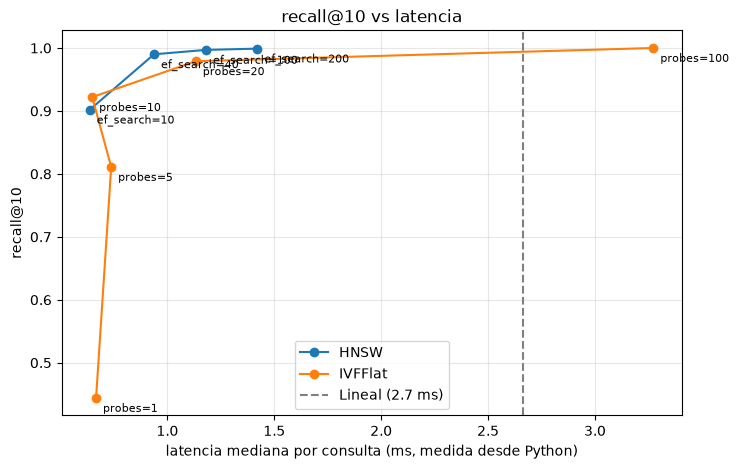

In [27]:
plt.figure(figsize=(8, 5))
for indice, g in tabla[tabla.indice != "Lineal"].groupby("indice"):
    plt.plot(g.latencia_ms, g["recall@10"], marker="o", label=indice)
    for _, r in g.iterrows():
        plt.annotate(r.parametro, (r.latencia_ms, r["recall@10"]), textcoords="offset points", xytext=(5, -10), fontsize=8)
plt.axvline(ms_lineal, color="gray", linestyle="--", label=f"Lineal ({ms_lineal:.1f} ms)")
plt.xlabel("latencia mediana por consulta (ms, medida desde Python)")
plt.ylabel("recall@10")
plt.title("recall@10 vs latencia")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

1. El que se acerca más es HNSW, con ef_search = 40 ya llega a 0.99 en 0.94 ms, mientras IVFFlat necesita probes = 20 para llegar a 0.98 en 1.13 ms. Comparado con la lineal se demora menos en llegar a ese recall
2. Con probes = 100 se revisan todos los clusters, da recall 1 como la lineal pero tarda más (3.27 ms vs 2.66 ms), porque recorre todo y además paga el costo del índice
3. Los índices no exploran todo el espacio porque tardaría mucho, sino que ven por rangos o vecinos cercanos, mientras en la lineal se recorre toda la data. En IVFFlat el vecino puede estar en un cluster que no se revisó y en HNSW el recorrido del grafo puede no llegar a él

### P4.2 Rendimiento vs tamaño

In [28]:
def execution_time_ms(q, k=10, op="<->"):
    cur.execute(f"EXPLAIN ANALYZE SELECT id FROM face_embeddings ORDER BY embedding {op} %s LIMIT %s", (q, k))
    linea = cur.fetchall()[-1][0]
    return float(linea.split(":")[1].split()[0])

def mediana_explain(q, repeticiones=11):
    tiempos = [execution_time_ms(q) for _ in range(repeticiones)]
    return statistics.median(tiempos[1:])

def tiempo_promedio(qs):
    return np.mean([mediana_explain(q) for q in qs])

In [29]:
qs_tiempo = consultas.embedding.iloc[:10].tolist()
resultados = []

for N in [1000, 2000, 4000, 8000, 12000]:
    cur.execute("DROP INDEX IF EXISTS face_ivf")
    cur.execute("DROP INDEX IF EXISTS face_hnsw")
    cur.execute("TRUNCATE face_embeddings RESTART IDENTITY")
    execute_values(cur, "INSERT INTO face_embeddings (name, path, embedding) VALUES %s",
                   list(base.head(N).itertuples(index=False, name=None)))
    cur.execute("ANALYZE face_embeddings")
    exactos_N = [knn_lineal(q, 10) for q in consultas.embedding]

    cur.execute("SET enable_indexscan = off")
    lineal_ms = tiempo_promedio(qs_tiempo)
    cur.execute("RESET enable_indexscan")

    lists = round(np.sqrt(N))
    cur.execute(f"CREATE INDEX face_ivf ON face_embeddings USING ivfflat (embedding vector_l2_ops) WITH (lists = {lists})")
    cur.execute("ANALYZE face_embeddings")
    for probes in sorted({p for p in [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 40, 50] if p < lists} | {lists}):
        cur.execute(f"SET ivfflat.probes = {probes}")
        recall_ivf, _ = evaluar(exactos_N)
        if recall_ivf >= 0.95:
            break
    cur.execute("SET enable_seqscan = off")
    ivf_ms = tiempo_promedio(qs_tiempo)
    cur.execute("RESET enable_seqscan")
    cur.execute("DROP INDEX face_ivf")

    cur.execute("CREATE INDEX face_hnsw ON face_embeddings USING hnsw (embedding vector_l2_ops) WITH (m = 16, ef_construction = 64)")
    cur.execute("ANALYZE face_embeddings")
    for ef in [10, 20, 40, 60, 80, 100, 150, 200, 300, 400]:
        cur.execute(f"SET hnsw.ef_search = {ef}")
        recall_hnsw, _ = evaluar(exactos_N)
        if recall_hnsw >= 0.95:
            break
    cur.execute("SET enable_seqscan = off")
    hnsw_ms = tiempo_promedio(qs_tiempo)
    cur.execute("RESET enable_seqscan")
    cur.execute("DROP INDEX face_hnsw")

    resultados.append({"N": N, "lineal_ms": lineal_ms,
                       "ivf_lists": lists, "ivf_probes": probes, "ivf_recall": recall_ivf, "ivf_ms": ivf_ms,
                       "hnsw_ef_search": ef, "hnsw_recall": recall_hnsw, "hnsw_ms": hnsw_ms})
    print(resultados[-1])

escala = pd.DataFrame(resultados)
escala

{'N': 1000, 'lineal_ms': 0.20494999999999997, 'ivf_lists': 32, 'ivf_probes': 10, 'ivf_recall': 0.9630000000000001, 'ivf_ms': 0.062450000000000006, 'hnsw_ef_search': 20, 'hnsw_recall': 0.9860000000000001, 'hnsw_ms': 0.07705}


{'N': 2000, 'lineal_ms': 0.40305, 'ivf_lists': 45, 'ivf_probes': 12, 'ivf_recall': 0.955, 'ivf_ms': 0.1051, 'hnsw_ef_search': 20, 'hnsw_recall': 0.9760000000000001, 'hnsw_ms': 0.08230000000000001}


{'N': 4000, 'lineal_ms': 0.7983, 'ivf_lists': 63, 'ivf_probes': 15, 'ivf_recall': 0.9620000000000002, 'ivf_ms': 0.18225000000000002, 'hnsw_ef_search': 20, 'hnsw_recall': 0.96, 'hnsw_ms': 0.09780000000000001}


{'N': 8000, 'lineal_ms': 1.6944, 'ivf_lists': 89, 'ivf_probes': 15, 'ivf_recall': 0.968, 'ivf_ms': 0.2776, 'hnsw_ef_search': 40, 'hnsw_recall': 0.9750000000000001, 'hnsw_ms': 0.19324999999999998}


{'N': 12000, 'lineal_ms': 2.4207500000000004, 'ivf_lists': 110, 'ivf_probes': 15, 'ivf_recall': 0.9550000000000002, 'ivf_ms': 0.3782, 'hnsw_ef_search': 20, 'hnsw_recall': 0.9570000000000001, 'hnsw_ms': 0.12294999999999998}


,N,lineal_ms,ivf_lists,ivf_probes,ivf_recall,ivf_ms,hnsw_ef_search,hnsw_recall,hnsw_ms
0,1000,0.20495,32,10,0.963,0.06245,20,0.986,0.07705
1,2000,0.40305,45,12,0.955,0.10510,20,0.976,0.08230
2,4000,0.79830,63,15,0.962,0.18225,20,0.960,0.09780
3,8000,1.69440,89,15,0.968,0.27760,40,0.975,0.19325
4,12000,2.42075,110,15,0.955,0.37820,20,0.957,0.12295


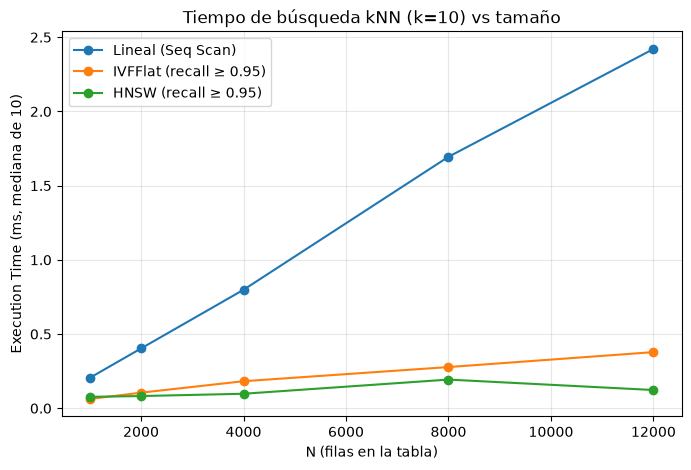

In [30]:
plt.figure(figsize=(8, 5))
plt.plot(escala.N, escala.lineal_ms, marker="o", label="Lineal (Seq Scan)")
plt.plot(escala.N, escala.ivf_ms, marker="o", label="IVFFlat (recall ≥ 0.95)")
plt.plot(escala.N, escala.hnsw_ms, marker="o", label="HNSW (recall ≥ 0.95)")
plt.xlabel("N (filas en la tabla)")
plt.ylabel("Execution Time (ms, mediana de 10)")
plt.title("Tiempo de búsqueda kNN (k=10) vs tamaño")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

La lineal crece mucho, con 12 veces más filas tarda ~12 veces más porque compara con todas. IVFFlat crece poco, ~6 veces, porque solo revisa algunos clusters, y HNSW casi no crece porque salta por el grafo. Es un escalamiento entendible por la complejidad, la lineal es O(N) y HNSW es casi logarítmico

In [31]:
cur.execute("TRUNCATE face_embeddings RESTART IDENTITY")
execute_values(cur, "INSERT INTO face_embeddings (name, path, embedding) VALUES %s",
               list(base.itertuples(index=False, name=None)))
cur.execute("CREATE INDEX face_hnsw ON face_embeddings USING hnsw (embedding vector_l2_ops) WITH (m = 16, ef_construction = 64)")
cur.execute("ANALYZE face_embeddings")
cur.execute("SELECT COUNT(*) FROM face_embeddings")
print("tabla recargada:", cur.fetchone()[0], "filas")

tabla recargada: 13076 filas


### P4.3 Conclusiones

**Ventajas y desventajas**
- **Lineal:** siempre da los resultados exactos, pero tarda más porque explora todo el espacio
- **IVFFlat:** hace k-means para agrupar a los más parecidos y solo explora los probes más cercanos, el espacio de búsqueda es menor y es más rápido. Se construye rápido (0.29 s) y ocupa poco (7.4 MB), pero hay riesgo de no obtener el más parecido y cuando se insertan nuevos los centroides quedan desactualizados, entonces conviene reconstruirlo
- **HNSW:** arma un grafo con los vecinos cercanos en varios niveles y va bajando hasta llegar al más cercano. Es el más rápido (llega a recall 0.99 en 0.94 ms), pero pesa más (10 MB) y tarda más en construirse (0.97 s)

**Con millones de vectores**

Crear los embeddings tardaría más, pero eso se hace una sola vez. En la búsqueda, la lineal tardaría mucho más porque crece igual que los datos. Con IVFFlat solo se revisa una fracción, pero se vuelve pesada la construcción. En HNSW el grafo va a necesitar más espacio y tiempo de construcción

**Casos reales**
- Control de acceso a UTEC con reconocimiento facial, se busca la cara entre todos los alumnos para dejar entrar
- Un buscador tipo Google Lens que recomienda más fotos de la misma persona, por ejemplo más fotos de Zendaya o Nicole Kidman

---
## Limpieza de datos biométricos

In [32]:
cur.execute("DELETE FROM face_embeddings WHERE path LIKE %s", ("%mi_foto%",))
print("filas borradas:", cur.rowcount)
del mi_foto

filas borradas: 0
